* I-JEPA


#### Goals
- 이미지 패치를 ViT 토큰으로 바꾸는 경로 확인
- multi-block mask에서 context는 크게, target block은 여러 개라는 점 확인
- loss가 block별 embedding MSE의 평균이라는 점 확인


#### Contents
1. Implementation
    <br>1.1 patch와 mask
2. Experiment
    <br>2.1 짧은 학습

논문: Assran et al., Self-Supervised Learning from Images with a Joint-Embedding Predictive Architecture, CVPR 2023.

노트북 기본값은 논문의 mask 비율을 유지하고 모델만 줄였다. target block 4개, block 면적 15–20%, context block 면적 85–100%, context에서 target과 겹치는 패치는 제거, target encoder는 이미지 전체를 보고 EMA로 갱신, loss는 MSE.


## 1. Implementation


In [1]:
import sys
from pathlib import Path

import torch

candidates = [Path.cwd(), Path.cwd() / "jepa"]
for cand in candidates:
    module_dir = cand / "modules"
    if module_dir.is_dir():
        sys.path.insert(0, str(module_dir))
        break
else:
    raise FileNotFoundError("jepa/modules 를 찾지 못했다. 노트북 cwd 를 ai-lab 또는 ai-lab/jepa 로 둔다.")

torch.manual_seed(0)
device = torch.device("cpu")
print("device", device)

from ijepa import IJEPA, sample_ijepa_masks

model = IJEPA(image_size=32, patch_size=4, embed_dim=96, depth=2, num_heads=4, num_targets=4).to(device)
images = torch.rand(4, 1, 32, 32, device=device)
print("grid", model.grid, "patches", model.grid * model.grid)
context_idx, targets, view = sample_ijepa_masks(model.grid, num_targets=4)
print("context patches", int(context_idx.numel()))
print("target patches per block", [int(t.numel()) for t in targets])


device cpu
grid 8 patches 64
context patches 36
target patches per block [9, 12, 9, 9]


#### 1.1 patch와 mask

view 값: 0은 context block 밖, 1은 context, 2 이상은 target block 번호. target끼리는 겹칠 수 있다.


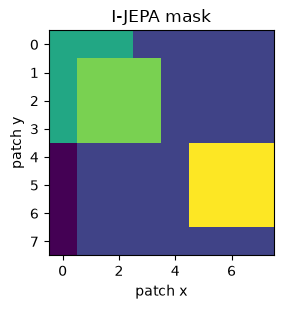

mse 1.0346


In [2]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(3.2, 3.2))
ax.imshow(view.numpy(), vmin=0, vmax=max(2, int(view.max())), interpolation="nearest")
ax.set_title("I-JEPA mask")
ax.set_xlabel("patch x")
ax.set_ylabel("patch y")
fig.tight_layout()
plt.show()

loss = model(images)
print("mse", round(loss.item(), 4))


## 2. Experiment

#### 2.1 짧은 학습

이미지는 균등 노이즈다. 여기서는 학습 곡선이 아니라 forward, backward, EMA가 논문과 같은 자리인지를 확인한다.


In [3]:
optimizer = torch.optim.AdamW(model.trainable_parameters(), lr=1e-3, weight_decay=0.05)
history = []
for step in range(6):
    optimizer.zero_grad()
    loss = model(images)
    loss.backward()
    optimizer.step()
    model.update_target(momentum=0.996)
    history.append(loss.item())
print([round(v, 4) for v in history])


[1.0334, 0.7144, 0.6355, 0.5635, 0.4942, 0.4458]
